# Cursor ML workbook

This is a real Jupyter workbook executed in Cursor with the project-local kernel.

In [1]:
import platform
import sys

import torch

from ml_lab.device import device_report, select_device

device = select_device("auto")
print(
    {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "torch": torch.__version__,
    }
)
print(device_report().as_dict())

{'python': '3.12.12', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'torch': '2.11.0'}
{'requested': 'auto', 'selected': 'mps', 'torch_version': '2.11.0', 'python_architecture': 'arm64', 'cuda_available': False, 'mps_available': True, 'cuda_device': None}


In [2]:
left = torch.ones((128, 128), device=device)
right = torch.full((128, 128), 2.0, device=device)
product = left @ right
print(
    {
        "device": str(product.device),
        "shape": tuple(product.shape),
        "sample": float(product[0, 0].cpu()),
    }
)

{'device': 'mps:0', 'shape': (128, 128), 'sample': 256.0}


In [3]:
x = torch.randn(32, 4, device=device, requires_grad=True)
weights = torch.randn(4, 1, device=device, requires_grad=True)
loss = ((x @ weights) ** 2).mean()
loss.backward()
print(
    {
        "loss": float(loss.detach().cpu()),
        "gradient_norm": float(weights.grad.norm().cpu()),
    }
)

{'loss': 0.7434486150741577, 'gradient_norm': 1.6641992330551147}


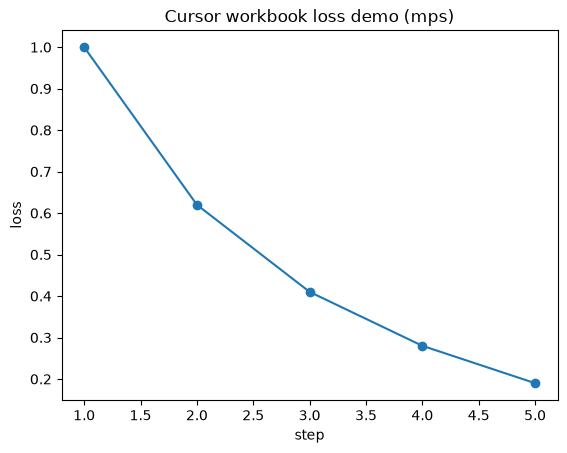

In [4]:
import matplotlib.pyplot as plt

steps = list(range(1, 6))
losses = [1.0, 0.62, 0.41, 0.28, 0.19]
plt.plot(steps, losses, marker="o")
plt.title(f"Cursor workbook loss demo ({device})")
plt.xlabel("step")
plt.ylabel("loss")
plt.show()